# Case Study 13 — "juta bina dori wala": Hinglish Search Query Translation, Language ID and NLP Evaluation in Search

**Priority:** ★★ Good to have · **Reference:** Case Study 13 — *Flipkart: Hinglish search query translation* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Search / Query Understanding, Product (search), Growth, Finance
**Data:** ⚠️ **SYNTHETIC** (D-13-01). Query logs and tagged sets are confidential; this is a simulation of transliterated Hinglish queries with a hidden true translation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs13_hinglish_search_queries.ipynb`

## 0. Executive Summary for Business

«EXEC»

## 1. The Problem in Simple English

Many Indian shoppers type queries in **Hinglish**: Hindi words written in English letters, often mixed with English words, with no standard spelling ("juta", "jootaa", "joote" all mean *shoes*). The search engine behind the app understands English product titles. If it cannot read the query, the shopper sees poor or empty results and may leave.

The fix is to **translate the Hinglish query into English** before search, fast enough that the shopper does not notice. Leaders and interviewers want to know:
1. How do we **detect** which queries (and which words) are Hinglish without breaking normal English queries?
2. How good is a translator trained on **cheap noisy labels** (a third-party API) compared with a small set of **human labels**, and how many human labels do we need?
3. Where does it fail: **tail queries, spelling variants, "articulation gap" phrases** such as "kapde dhone wali machine" (washing machine)?
4. Does better translation actually produce **better search results**, and what is that worth in ₹?
5. How do we **evaluate** it (exact match, BLEU, search success) and keep latency low?

## 2. Reference from the Case File

### (a) What Flipkart did — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | About **21%** of Flipkart queries are Hinglish. Translating to English lets the existing English search stack serve them. Stated difficulties: no parallel data, spelling errors, brand misspellings, ambiguous language identification, "articulation gap" queries ("juta bina dori wala" for "shoe without lace") |
| Data | About 5M unlabelled Hindi/Hinglish queries pseudo-labelled with third-party translation and transliteration APIs; an in-house tagged set of about 70k queries (under 1.5% of the labelled set); 15k manually tagged test queries balanced across Head, Torso and Tail; an 80k per-word language-ID set |
| Approach | Per-word language identification; sequence-to-sequence translation trained in two stages (pseudo-labels, then human labels); augmentation (masking, auto-encoder, DropChar, word-order permutation); distillation to a one-layer quantised student for latency |
| Models and metrics | BART-base chosen; SacreBLEU on the Hinglish test set: Azure 25.5, Google 35.8, BART with augmentation 51.3. Language ID CRF best (precision 0.84, recall 0.72); the keyword baseline had recall 28%. Distillation: BLEU 51.3 to 50.8 with p95 latency about 200 ms to about 47 ms |
| Impact | "Live on Flipkart" and "A/B testing used" are the authors' own claims. **No quantified business metric is given** |

**Source:** arXiv 2208.03713, "Study of Encoder-Decoder Architectures for Code-Mix Search Query Translation" (7 Aug 2022). Evidence level: medium (company paper with method detail, no business numbers).

> **Honest scope.** Public method detail is thin beyond the paper, and the paper's data and models are not public. This notebook is an **interview-standard solution on simulated data using scikit-learn-level methods, not a reproduction of Flipkart's system**. No BLEU figure here is comparable to the paper's.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 150,000 queries over 90 days; about 21% contain Hindi words (calibrated to the documented share). 49 items, 9 colours, 5 audiences, 5 features, price caps, brands; 12 template shapes including Hindi word order ("mahila ke liye joote" for *shoes for women*) and 10 articulation-gap phrases. Hindi words get random transliteration variants; English words get typos |
| Labels | A noisy **third-party-API-style** translation for every query (word for word, standard spellings only, no reordering); a small **human-tagged** set (9,000 Hinglish and 6,000 English train; 3,000 Hinglish test balanced over Head / Torso / Tail, plus 3,000 English test) with true translation and per-word language tags |
| Methods | **Language ID** (keyword, seen-word lookup, Naive Bayes, logistic on character n-grams, logistic with neighbour context); **translator** = word-translation lexicon induced from parallel queries (association statistics) + character n-gram classifier for unseen spellings + a learned reordering step; two-stage training (API pseudo-labels, then human labels); ablations; query memory |
| Statistics added | Wilson CIs; McNemar (Holm); bootstrap BLEU CIs; chi-square across strata; learning curve for human labels; DropChar augmentation test; search **success@10** before and after translation on a synthetic catalogue; latency; sample sizes for test sets and an A/B test |

### (c) How the industry uses this

Code-mixed query understanding is used by Indian marketplaces and quick-commerce apps (Flipkart, Amazon India, Meesho, Myntra, Swiggy Instamart) as an early step in search: detect, normalise or translate, then retrieve and rank. Typical stacks combine a language-ID model, a spelling-variant normaliser, a translation or transliteration model, and a query cache for head queries. It is a good interview topic for NLP evaluation: noisy labels, stratified test sets, offline metric versus search outcome, latency budgets.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Can we serve the roughly one in five queries that are Hinglish as well as English ones, at production latency, and what is it worth? |
| Analytical | Which translator design recovers the true English query, for which queries does it fail, how many human labels are enough, and does it raise search success? |

**Hypotheses**
- **H1:** H0: the two-stage translator's exact-match rate equals the third-party API's (McNemar, Holm).
- **H2:** H0: adding human labels to pseudo-labels does not change accuracy (stage 2 vs stage 1; and learning curve in number of human labels).
- **H3:** H0: accuracy is the same for Head, Torso and Tail queries (chi-square); gap phrases are a separate failure class.
- **H4:** H0: language ID with neighbour context equals character-only language ID (McNemar on words).
- **H5:** H0: translating Hinglish queries does not change search success@10 on a catalogue (McNemar, paired bootstrap).
- **H6:** H0: a memoised student gives the same translations as the teacher at no lower latency.

**Primary metrics:** **exact match** with the true English query and **corpus BLEU** (own implementation, 4-gram); **search success@10** and MRR. **Diagnostic:** per-word language-ID precision / recall, damage to English queries, latency (p50, p95).

In [1]:
import sys, warnings, importlib, os, time, re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
T_START = time.time()
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian search query logs | **None.** Marketplace search logs are confidential. Public Hinglish corpora (social media, Hindi-English code-mixing sets) are not product-search queries and have no catalogue or true translation |
| **Decision** | Synthetic transliterated queries with a hidden true English translation and a small English catalogue, calibrated to the documented 21% Hinglish share (D-13-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs13.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 13 (Flipkart-style Hinglish search query translation)
==========================================================================================
THIS DATA IS SYNTHETIC. Flipkart's query logs and tagged sets are confidential and not public.

Documented context (arXiv 2208.03713, Kulkarni, Chennabasavaraj, Garera; Flipkart): about 21% of queries are Hinglish
(Hindi words typed in Latin script); no parallel data; spelling errors and brand misspellings; "articulation gap"
queries ("juta bina dori wala" for "shoe without lace"); pseudo-labels from third-party translation APIs, then a small
human-tagged set; test sets stratified Head / Torso / Tail.

Simulation (calibrated only to the 21% Hinglish share; everything else is assumed):
  * An intent (item, colour, audience, feature, price cap, adjective, brand) is drawn from long-tailed distributions.
  * It is rendered either in English, or in Hinglish: Hindi word order, Hindi words typed with random spelling
    variants, English words mixed in, occasional English-order Hinglish, and rare "articulation gap" phrases.
  * A noisy "third-party translation API" column (word-for-word, canonical spellings only, no reordering) gives the
    pseudo-labels. A small human-tagged set has the true English query and per-word language tags.
  * A small English product catalogue lets us measure search success before and after translation.
Hidden truth columns start with "_".

Outputs (written by the notebook): query_log.csv.gz, human_tagged.csv.gz, catalogue.csv.gz
"""
import random
import numpy as np
import pandas as pd

SEED = 42
N_QUERIES = 150_000
P_HI_MODE = 0.274          # chosen so that about 21% of queries contain at least one Hindi word

# ----- lexicon -------------------------------------------------------------------------------------------
# (English gold word, [Hindi spellings (canonical) with the first used most], group)
ITEMS = [("shoes", ["joote", "juta"], "wear"), ("mobile", [], "tech"), ("clothes", ["kapde"], "wear"), ("shirt", [], "wear"),
         ("watch", ["ghadi"], "wear"), ("slippers", ["chappal"], "wear"), ("bag", ["thaila"], "wear"), ("headphones", [], "tech"),
         ("charger", [], "tech"), ("cover", [], "tech"), ("jeans", [], "wear"), ("kurta", [], "wear"), ("tshirt", [], "wear"),
         ("saree", [], "wear"), ("laptop", [], "tech"), ("bottle", [], "home"), ("sunglasses", ["chashma"], "wear"),
         ("cap", ["topi"], "wear"), ("cooker", [], "home"), ("mixer", [], "home"), ("rice", ["chawal"], "food"),
         ("tea", ["chai"], "food"), ("oil", ["tel"], "food"), ("flour", ["atta"], "food"), ("chair", ["kursi"], "home"),
         ("table", ["mez"], "home"), ("bedsheet", ["chadar"], "home"), ("pillow", ["takiya"], "home"), ("fan", ["pankha"], "home"),
         ("mirror", ["sheesha"], "home"), ("toy", ["khilona"], "other"), ("book", ["kitab"], "other"), ("pen", ["kalam"], "other"),
         ("mattress", ["gadda"], "home"), ("curtains", ["parda"], "home"), ("utensils", ["bartan"], "home"), ("bucket", ["baalti"], "home"),
         ("lentils", ["dal"], "food"), ("sugar", ["cheeni"], "food"), ("milk", ["doodh"], "food"), ("salt", ["namak"], "food"),
         ("wardrobe", ["almari"], "home"), ("doll", ["gudiya"], "other"), ("wok", ["kadhai"], "home"), ("griddle", ["tawa"], "home"),
         ("scissors", ["kainchi"], "home"), ("lock", ["taala"], "home"), ("key", ["chaabi"], "home"), ("rope", ["rassi"], "home")]
COLOURS = [("black", ["kala"]), ("red", ["lal"]), ("blue", ["neela"]), ("white", ["safed"]), ("green", ["hara"]), ("yellow", ["peela"]),
           ("pink", ["gulabi"]), ("brown", ["bhoora"]), ("orange", ["narangi"])]
ADJ = {"wear": [("cheap", "sasta"), ("light", "halka"), ("strong", "mazboot"), ("long", "lamba"), ("big", "bada"), ("small", "chota")],
       "home": [("cheap", "sasta"), ("big", "bada"), ("small", "chota"), ("strong", "mazboot"), ("thick", "mota")],
       "tech": [("cheap", "sasta"), ("strong", "mazboot"), ("light", "halka")], "food": [("cheap", "sasta"), ("big", "bada")],
       "other": [("cheap", "sasta"), ("big", "bada"), ("small", "chota")]}
AUD = [("women", "mahila", "ladies"), ("men", "mard", "gents"), ("kids", "bachchon", "kids"), ("girls", "ladkiyon", "girls"), ("boys", "ladkon", "boys")]
FEAT = [("laces", "dori"), ("pockets", "jeb"), ("lid", "dhakkan"), ("handle", "hatthe"), ("wheels", "pahiye")]
BRANDS = ["nike", "adidas", "puma", "samsung", "boat", "redmi", "philips", "prestige", "bata", "levis", "realme", "sony", "hp", "milton", "wildcraft"]
PRICES = [199, 299, 399, 499, 599, 799, 999, 1499, 1999, 2999]
# articulation-gap phrases: (English gold, Hindi-typed variants, which tokens are English)
GAPS = [("washing machine", ["kapde dhone wali machine", "kapde dhone ki machine"]), ("earphones", ["kaan mein lagane wala", "kaan mein lagane wale speaker"]),
        ("hair dryer", ["baal sukhane wala", "baal sukhane ki machine"]), ("water heater", ["pani garam karne wala", "pani garam karne ki rod"]),
        ("iron", ["kapde press karne wala", "kapde press karne ki machine"]), ("pressure cooker", ["dal pakane ka bartan", "jaldi pakane wala bartan"]),
        ("trimmer", ["dadhi banane wali machine", "dadhi kaatne wali machine"]), ("mosquito racket", ["machhar maarne wala", "machhar maarne ka bat"]),
        ("power bank", ["mobile charge karne wala dabba", "phone charge karne ka dabba"]), ("laptop bag", ["laptop rakhne ka thaila", "laptop rakhne wala bag"])]
ENG_WORDS = {"machine", "speaker", "press", "rod", "bat", "mobile", "charge", "phone", "laptop", "bag"}
FUNC = {"ke": "", "liye": "for", "bina": "without", "saath": "with", "wala": "", "wali": "", "wale": "", "neeche": "under", "se": "", "kam": "under", "tak": "under", "aur": "and"}

# canonical Hindi -> English (what a "third-party API" knows)
CANON = {}
for en, his, g in ITEMS:
    for h in his: CANON[h] = en
for en, his in COLOURS:
    for h in his: CANON[h] = en
for g, lst in ADJ.items():
    for en, h in lst: CANON[h] = en
for en, h, _ in AUD: CANON[h] = en
for en, h in FEAT: CANON[h] = en
CANON.update({k: v for k, v in FUNC.items()})
ALL_ENGLISH_ITEMS = [i[0] for i in ITEMS] + [g[0] for g in GAPS]

RULES = [("aa", "a"), ("a", "aa"), ("ee", "i"), ("i", "ee"), ("oo", "u"), ("u", "oo"), ("sh", "s"), ("s", "sh"), ("v", "w"), ("w", "v"),
         ("ch", "chh"), ("chh", "ch"), ("th", "t"), ("t", "th"), ("dh", "d"), ("ai", "ay"), ("au", "ow"), ("o", "oo"), ("e", "a"), ("k", "c")]


def variant(tok, rnd, p=0.6):
    """Random transliteration variant of a Hindi word typed in Latin script."""
    if rnd.random() > p or len(tok) < 3: return tok
    s = tok
    for _ in range(rnd.choice([1, 1, 1, 2])):
        ap = [r for r in RULES if r[0] in s]
        if not ap: break
        a, b = rnd.choice(ap); idx = [i for i in range(len(s)) if s.startswith(a, i)]; i = rnd.choice(idx); s = s[:i] + b + s[i + len(a):]
    r = rnd.random()
    if r < 0.12 and s[-1] in "aei": s = s[:-1]
    elif r < 0.17 and len(s) > 4: i = rnd.randrange(1, len(s) - 1); s = s[:i] + s[i + 1:]
    elif r < 0.21: i = rnd.randrange(1, len(s)); s = s[:i] + s[i - 1] + s[i:]
    return s


def typo(tok, rnd, p=0.04):
    if len(tok) < 5 or rnd.random() > p: return tok
    i = rnd.randrange(1, len(tok) - 1)
    return tok[:i] + tok[i + 1:] if rnd.random() < 0.5 else tok[:i] + tok[i + 1] + tok[i] + tok[i + 2:]


def _zipf(n, s, rnd_unused=None):
    w = 1.0 / (np.arange(n) + 1.5) ** s; return (w / w.sum()).tolist()


TEMPLATES = ["item", "col_item", "item_adj", "aud_item", "aud_col_item", "without", "with", "price", "brand_item", "item_and", "gap", "adj_col_item"]
TW = [0.27, 0.15, 0.07, 0.12, 0.04, 0.04, 0.04, 0.08, 0.10, 0.03, 0.03, 0.03]


def make_intent(rnd, wi, wc, wa, wf, wp, wb):
    t = rnd.choices(TEMPLATES, TW)[0]; it = {"template": t}
    if t == "gap":
        g = rnd.randrange(len(GAPS)); it.update(item=GAPS[g][0], gap=g, group="home"); return it
    k = rnd.choices(range(len(ITEMS)), wi)[0]; en, his, grp = ITEMS[k]; it.update(item=en, k=k, group=grp)
    if t in ("col_item", "aud_col_item", "adj_col_item"): it["col"] = rnd.choices(range(len(COLOURS)), wc)[0]
    if t in ("aud_item", "aud_col_item"): it["aud"] = rnd.choices(range(len(AUD)), wa)[0]
    if t in ("item_adj", "adj_col_item"): it["adj"] = rnd.randrange(len(ADJ[grp]))
    if t in ("without", "with"): it["feat"] = rnd.choices(range(len(FEAT)), wf)[0]
    if t == "price": it["price"] = rnd.choices(PRICES, wp)[0]
    if t == "brand_item": it["brand"] = rnd.choices(BRANDS, wb)[0]
    if t == "item_and":
        j = rnd.choices(range(len(ITEMS)), wi)[0]
        if j == k: j = (j + 1) % len(ITEMS)
        it["item2"] = ITEMS[j][0]; it["k2"] = j
    if t in ("aud_item", "aud_col_item") and grp not in ("wear",): it["template"] = "item" if t == "aud_item" else "col_item"; it.pop("aud")
    if "col" in it and grp in ("food", "other"): it["template"] = {"col_item": "item", "aud_col_item": "aud_item", "adj_col_item": "item_adj"}[it["template"]]; it.pop("col");
    if it["template"] == "item_adj" and "adj" not in it: it["adj"] = rnd.randrange(len(ADJ[grp]))
    if it["template"] == "aud_item" and "aud" not in it: it["aud"] = rnd.choices(range(len(AUD)), wa)[0]
    return it


def gold_english(it):
    t = it["template"]; item = it["item"]; grp = it["group"]
    col = COLOURS[it["col"]][0] if "col" in it else None; aud = AUD[it["aud"]][0] if "aud" in it else None
    adj = ADJ[grp][it["adj"]][0] if "adj" in it else None
    if t == "gap": return item
    if t == "item": return item
    if t == "col_item": return f"{col} {item}"
    if t == "item_adj": return f"{adj} {item}"
    if t == "aud_item": return f"{item} for {aud}"
    if t == "aud_col_item": return f"{col} {item} for {aud}"
    if t == "without": return f"{item} without {FEAT[it['feat']][0]}"
    if t == "with": return f"{item} with {FEAT[it['feat']][0]}"
    if t == "price": return f"{item} under {it['price']}"
    if t == "brand_item": return f"{it['brand']} {item}"
    if t == "item_and": return f"{item} and {it['item2']}"
    if t == "adj_col_item": return f"{adj} {col} {item}"


def _hi_pick(his, rnd):
    if not his: return None
    return his[0] if len(his) == 1 or rnd.random() < 0.6 else his[1]


def render(it, hi_mode, rnd):
    """Return list of (token, lang) with lang in {'h','e'}."""
    t = it["template"]; grp = it["group"]
    E = lambda w: [(x, "e") for x in w.split()]
    if t == "gap":
        if not hi_mode: return E(it["item"])
        ph = rnd.choice(GAPS[it["gap"]][1]); return [(variant(w, rnd) if w not in ENG_WORDS else w, "e" if w in ENG_WORDS else "h") for w in ph.split()]
    if not hi_mode:
        return [(typo(w, rnd), "e") for w, _l in E(gold_english(it))]
    en_order = rnd.random() < 0.15; P = 0.85
    def item_tok(en, his):
        h = _hi_pick(his, rnd)
        return [(variant(h, rnd), "h")] if (h and rnd.random() < P) else [(typo(en, rnd), "e")]
    en_, his_, _g = ITEMS[it["k"]]; IT = item_tok(en_, his_)
    def col_tok():
        en, his = COLOURS[it["col"]]; return [(variant(his[0], rnd), "h")] if rnd.random() < P else [(en, "e")]
    def adj_tok():
        en, h = ADJ[grp][it["adj"]]; return [(variant(h, rnd), "h")] if rnd.random() < P else [(en, "e")]
    def aud_tok():
        en, h, alt = AUD[it["aud"]]; return [(variant(h, rnd), "h")] if rnd.random() < P else [(alt, "e")]
    def feat_tok():
        en, h = FEAT[it["feat"]]; return [(variant(h, rnd), "h")] if rnd.random() < P else [(en, "e")]
    F = lambda w: [(variant(w, rnd, 0.5), "h")]
    if t == "item": return IT
    if t == "col_item": return col_tok() + IT
    if t == "adj_col_item": return adj_tok() + col_tok() + IT
    if t == "item_adj": return (adj_tok() + IT) if en_order else (IT + adj_tok())
    if t == "aud_item": return (IT + [("for", "e")] + aud_tok()) if en_order else (aud_tok() + F("ke") + F("liye") + IT)
    if t == "aud_col_item": return (col_tok() + IT + [("for", "e")] + aud_tok()) if en_order else (aud_tok() + F("ke") + F("liye") + col_tok() + IT)
    if t == "without": return (IT + [("without", "e")] + feat_tok()) if en_order else (IT + F("bina") + feat_tok() + F(rnd.choice(["wala", "wala", "wali", "wale"])))
    if t == "with":
        if en_order: return IT + [("with", "e")] + feat_tok()
        return (feat_tok() + F(rnd.choice(["wala", "wali", "wale"])) + IT) if rnd.random() < 0.6 else (IT + feat_tok() + F("ke") + F("saath"))
    if t == "price":
        n = [(str(it["price"]), "e")]
        if en_order: return IT + [("under", "e")] + n
        r = rnd.random(); return (n + F("ke") + F("neeche") + IT) if r < 0.4 else ((IT + n + F("se") + F("kam")) if r < 0.75 else (IT + n + F("tak")))
    if t == "brand_item": return [(it["brand"], "e")] + IT
    if t == "item_and":
        en2, his2, _ = ITEMS[it["k2"]]; return IT + (F("aur") if not en_order else [("and", "e")]) + item_tok(en2, his2)
    raise ValueError(t)


def api_translate(tokens, rnd):
    """Noisy third-party API: word for word, canonical spellings only, no reordering, 6% random mistranslations."""
    out = []
    vocab = list(set(CANON.values()))
    for w in tokens:
        if w in CANON:
            e = CANON[w]
            if rnd.random() < 0.06 and e: e = rnd.choice(vocab)
            if e: out.append(e)
        else:
            out.append(w)
    return " ".join(out)


def build_catalogue(rnd, per_item=200):
    rows = []; pid = 0
    for en in ALL_ENGLISH_ITEMS:
        grp = next((g for e, _h, g in ITEMS if e == en), "home")
        for _ in range(per_item):
            col = rnd.choice(COLOURS)[0] if grp in ("wear", "home", "tech") and rnd.random() < 0.65 else None
            aud = rnd.choice(AUD)[0] if grp == "wear" and rnd.random() < 0.8 else None
            feat = rnd.choice(FEAT)[0] if grp in ("wear", "home") and rnd.random() < 0.3 else None
            brand = rnd.choice(BRANDS); price = int(round(np.exp(np.log(900) + rnd.gauss(0, 0.9))))
            extra = rnd.choice(["", "", "stylish", "premium", "pack of 2", "new", "combo"])
            title = " ".join(x for x in [brand, col, en, ("for " + aud) if aud else None, ("with " + feat) if feat else None, extra] if x)
            rows.append((pid, title, en, col or "", aud or "", feat or "", brand, price)); pid += 1
    return pd.DataFrame(rows, columns=["product_id", "title", "item", "colour", "audience", "feature", "brand", "price_inr"])


def generate(seed=SEED, n=N_QUERIES):
    rnd = random.Random(seed)
    wi, wc, wa, wf, wp, wb = _zipf(len(ITEMS), 1.0), _zipf(len(COLOURS), 0.9), _zipf(len(AUD), 0.8), _zipf(len(FEAT), 0.8), _zipf(len(PRICES), 0.8), _zipf(len(BRANDS), 0.9)
    rows = []
    for q in range(n):
        it = make_intent(rnd, wi, wc, wa, wf, wp, wb); hi_mode = rnd.random() < P_HI_MODE
        toks = render(it, hi_mode, rnd); raw = " ".join(w for w, _ in toks); langs = " ".join(l for _, l in toks); gold = gold_english(it)
        if it["template"] == "item_and": gold_items = f"{it['item']}|{it['item2']}"
        else: gold_items = it["item"]
        rows.append((q, rnd.randrange(90), rnd.choices(["android", "ios", "web"], [0.72, 0.1, 0.18])[0], raw,
                     api_translate(raw.split(), rnd), gold, langs, it["template"], gold_items,
                     COLOURS[it["col"]][0] if "col" in it else "", AUD[it["aud"]][0] if "aud" in it else "", int("h" in langs.split()), int(it["template"] == "gap" and "h" in langs.split())))
    log = pd.DataFrame(rows, columns=["query_id", "day", "device", "raw_query", "api_translation", "_gold_en", "_tok_lang", "_template", "_items", "_colour", "_audience", "_is_hinglish", "_is_gap"])
    # strata by traffic share of Hinglish raw strings
    h = log[log._is_hinglish == 1]; vc = h.raw_query.value_counts(); cum = vc.cumsum() / vc.sum()
    stratum = pd.Series(np.where(cum <= 1 / 3, "head", np.where(cum <= 2 / 3, "torso", "tail")), index=vc.index)
    log["_stratum"] = np.where(log._is_hinglish == 1, log.raw_query.map(stratum), "")
    # human-tagged set: test (1,000 Hinglish per stratum + 3,000 English) and train pool (uniform draw)
    r2 = np.random.default_rng(seed + 1); test_ids = []
    for s in ("head", "torso", "tail"): test_ids += r2.choice(log.query_id[log._stratum == s].values, 1000, replace=False).tolist()
    test_ids += r2.choice(log.query_id[log._is_hinglish == 0].values, 3000, replace=False).tolist()
    rest = log[~log.query_id.isin(test_ids)]
    train_ids = r2.choice(rest.query_id[rest._is_hinglish == 1].values, 9000, replace=False).tolist() + r2.choice(rest.query_id[rest._is_hinglish == 0].values, 6000, replace=False).tolist()
    tag = log[log.query_id.isin(test_ids + train_ids)].copy(); tag["split"] = np.where(tag.query_id.isin(test_ids), "test", "train")
    tagged = tag[["query_id", "raw_query", "_gold_en", "_tok_lang", "split"]].rename(columns={"_gold_en": "human_translation", "_tok_lang": "human_token_lang"}).reset_index(drop=True)
    cat = build_catalogue(rnd)
    return log, tagged, cat


if __name__ == "__main__":
    import time
    t0 = time.time(); lg, tg, ct = generate(); print(len(lg), "queries,", round(lg._is_hinglish.mean(), 4), "Hinglish share,", len(tg), "tagged,", len(ct), "products,", round(time.time() - t0, 1), "s")
    print(lg.sample(12, random_state=1)[["raw_query", "_gold_en", "api_translation"]].to_string())
    print(lg[lg._is_hinglish == 1]._stratum.value_counts(), lg.raw_query[lg._is_hinglish == 1].nunique())

Overwriting data/generate_cs13.py


In [3]:
os.makedirs("data/cs13", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs13 as gen; importlib.reload(gen)
t0 = time.time(); log, tagged, cat = gen.generate(seed=SEED)
log.to_csv("data/cs13/query_log.csv.gz", index=False); tagged.to_csv("data/cs13/human_tagged.csv.gz", index=False); cat.to_csv("data/cs13/catalogue.csv.gz", index=False)
print(f"{len(log):,} queries | {log._is_hinglish.mean():.1%} Hinglish | {len(tagged):,} human-tagged | {len(cat):,} catalogue products | generated in {time.time() - t0:.0f}s")
log.head(6)

150,000 queries | 21.1% Hinglish | 21,000 human-tagged | 11,800 catalogue products | generated in 53s


,query_id,day,device,raw_query,api_translation,_gold_en,_tok_lang,_template,_items,_colour,_audience,_is_hinglish,_is_gap,_stratum
0,0,11,android,red shoes for women,red shoes for women,red shoes for women,e e e e,aud_col_item,shoes,red,women,0,0,
1,1,53,android,joote,shoes,shoes,h,item,shoes,,,1,0,head
2,2,43,android,shoes under 999,shoes under 999,shoes under 999,e e e,price,shoes,,,0,0,
3,3,10,android,lal shirt,red shirt,red shirt,h e,col_item,shirt,red,,1,0,head
4,4,89,web,shafed pankhaa,shafed pankhaa,white fan,h h,col_item,fan,white,,1,0,tail
5,5,40,android,kaala cover,kaala cover,black cover,h e,col_item,cover,black,,1,0,head


| Parameter | Value | Basis |
|---|---|---|
| Hinglish share | about 21% of queries contain at least one Hindi word | **Documented** (paper) |
| Scale | 150,000 queries, 49 items + 10 gap phrases, 11,800 catalogue products | Our assumption |
| Spelling | Hindi words get a random transliteration variant 60% of the time; English words get a typo 4% of the time | Our assumption (paper: spelling errors, no standard spelling) |
| Word order | Hindi order ("mahila ke liye joote") in 85% of Hinglish queries, English order with Hindi nouns in 15% | Our assumption |
| Articulation gap | 3% of intents, 10 phrases, whole-phrase meaning | **Documented** concept, our share |
| Pseudo-labels | API-style: standard spellings only, word for word, 6% random mistranslation | Our assumption (paper: third-party APIs) |
| Human tags | 9,000 + 6,000 train, 3,000 + 3,000 test | Scaled-down analogue of the paper's sets |
| Test strata | Head / Torso / Tail = thirds of Hinglish traffic by raw query string | Paper stratifies by Head / Torso / Tail |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("query_log: query_id, day, device, raw_query", "Query id, day 0 to 89, device, the typed query (lower case)"),
    ("api_translation", "Noisy third-party-API-style translation (the pseudo-label)"),
    ("_gold_en, _tok_lang, _template, _items, _colour, _audience, _is_hinglish, _is_gap, _stratum", "HIDDEN truth: true English query, per-word language tags (h/e), template, intended item(s), colour, audience, flags, Head/Torso/Tail"),
    ("human_tagged: query_id, raw_query, human_translation, human_token_lang, split", "Human-tagged queries with true English translation and per-word language tags; split = train / test"),
    ("catalogue: product_id, title, item, colour, audience, feature, brand, price_inr", "English catalogue used to measure search success"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs13/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"query_log: query_id, day, device, raw_query","Query id, day 0 to 89, device, the typed query..."
1,api_translation,Noisy third-party-API-style translation (the p...
2,"_gold_en, _tok_lang, _template, _items, _colou...","HIDDEN truth: true English query, per-word lan..."
3,"human_tagged: query_id, raw_query, human_trans...",Human-tagged queries with true English transla...
4,"catalogue: product_id, title, item, colour, au...",English catalogue used to measure search success


## 5. Data Quality Checks

In [5]:
H = log[log._is_hinglish == 1]; Eg = log[log._is_hinglish == 0]
tg = tagged.copy(); tg["toks"] = tg.raw_query.str.lower().str.split(); tg["tags"] = tg.human_token_lang.str.split()
trs = set(tg.raw_query[(tg.split == "train") & tg.human_token_lang.str.contains("h")]); tes = tg[(tg.split == "test") & tg.human_token_lang.str.contains("h")]
checks = {"empty queries": int((log.raw_query.str.strip() == "").sum()), "non-ASCII queries": int((~log.raw_query.map(str.isascii)).sum()),
          "tagged rows with token / tag length mismatch": int((tg.toks.map(len) != tg.tags.map(len)).sum()),
          "unique raw strings (all queries)": int(log.raw_query.nunique()), "unique raw strings (Hinglish)": int(H.raw_query.nunique()),
          "Hinglish test queries whose exact string is in the human train set": int(tes.raw_query.isin(trs).sum()),
          "Hinglish queries where the API left the query unchanged": int((H.raw_query == H.api_translation).sum())}
print(pd.Series(checks, name="count").to_string())
print(f"\nHinglish share {log._is_hinglish.mean():.2%} | Hinglish queries by raw-string traffic: head {np.mean(H._stratum == 'head'):.1%}, torso {np.mean(H._stratum == 'torso'):.1%}, tail {np.mean(H._stratum == 'tail'):.1%} | gap-phrase queries {int(log._is_gap.sum()):,}")
print(f"Mean tokens per query: English {Eg.raw_query.str.split().map(len).mean():.2f}, Hinglish {H.raw_query.str.split().map(len).mean():.2f}")

empty queries                                                             0
non-ASCII queries                                                         0
tagged rows with token / tag length mismatch                              0
unique raw strings (all queries)                                      26826
unique raw strings (Hinglish)                                         18203
Hinglish test queries whose exact string is in the human train set     1187
Hinglish queries where the API left the query unchanged               11907

Hinglish share 21.07% | Hinglish queries by raw-string traffic: head 33.3%, torso 33.3%, tail 33.3% | gap-phrase queries 1,250


Mean tokens per query: English 1.92, Hinglish 2.48


**Observation:** «O5»

## 6. Exploratory Data Analysis

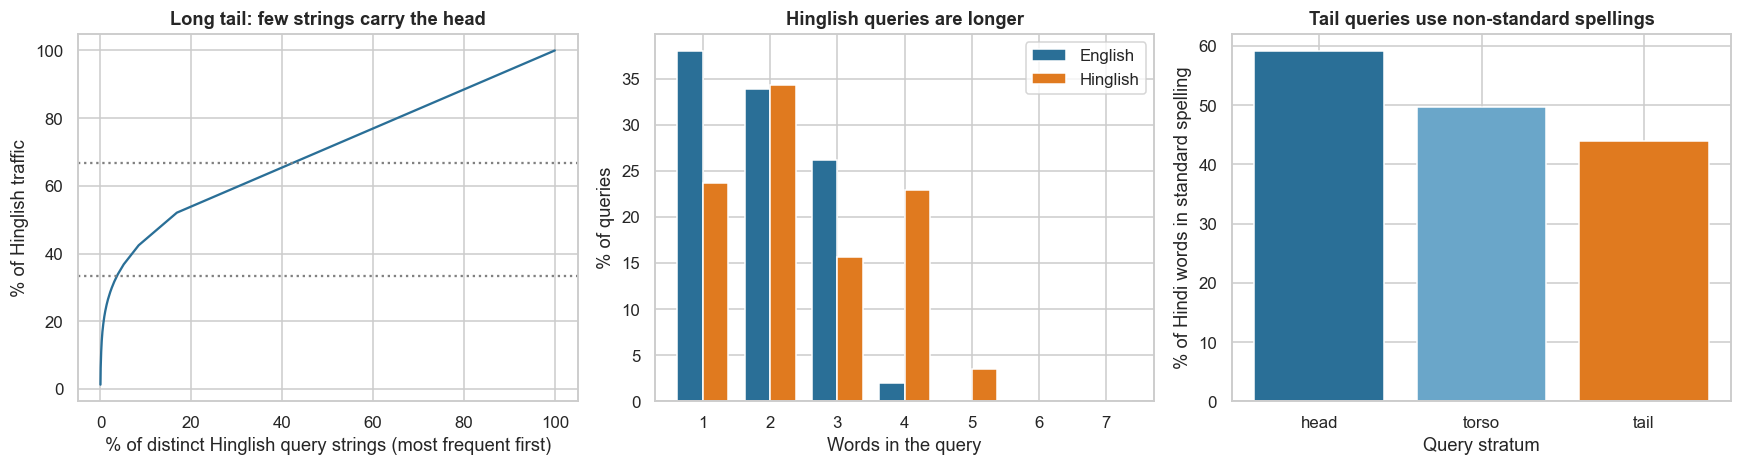

Distinct Hinglish strings: 18,203; the top 655 strings = one third of traffic | Hindi words in standard spelling: head 59%, torso 50%, tail 44% | distinct Hindi spellings: 2,377 for 75 standard words


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
vc = H.raw_query.value_counts(); cum = vc.cumsum().values / vc.sum(); rk = np.arange(1, len(vc) + 1) / len(vc) * 100
axes[0].plot(rk, cum * 100, color="#2a6f97"); axes[0].axhline(33.3, color="grey", ls=":"); axes[0].axhline(66.7, color="grey", ls=":")
axes[0].set_xlabel("% of distinct Hinglish query strings (most frequent first)"); axes[0].set_ylabel("% of Hinglish traffic"); axes[0].set_title("Long tail: few strings carry the head")
lh = H.raw_query.str.split().map(len).value_counts(normalize=True).sort_index(); le = Eg.raw_query.str.split().map(len).value_counts(normalize=True).sort_index()
w = 0.38; xs = np.arange(1, 8); axes[1].bar(xs - w / 2, [le.get(x, 0) * 100 for x in xs], w, label="English", color="#2a6f97"); axes[1].bar(xs + w / 2, [lh.get(x, 0) * 100 for x in xs], w, label="Hinglish", color="#e07a1f")
axes[1].set_xlabel("Words in the query"); axes[1].set_ylabel("% of queries"); axes[1].set_title("Hinglish queries are longer"); axes[1].legend()
hi_tok = [(wd, s) for raw, tl, s in zip(H.raw_query, H._tok_lang, H._stratum) for wd, l in zip(raw.split(), tl.split()) if l == "h"]
std = pd.DataFrame(hi_tok, columns=["tok", "stratum"]); std["standard"] = std.tok.isin(gen.CANON.keys()); sp = std.groupby("stratum").standard.mean().reindex(["head", "torso", "tail"])
axes[2].bar(sp.index, sp.values * 100, color=["#2a6f97", "#6aa6c9", "#e07a1f"]); axes[2].set_xlabel("Query stratum"); axes[2].set_ylabel("% of Hindi words in standard spelling"); axes[2].set_title("Tail queries use non-standard spellings")
plt.tight_layout(); plt.show()
print(f"Distinct Hinglish strings: {len(vc):,}; the top {int((cum <= 1 / 3).sum())} strings = one third of traffic | Hindi words in standard spelling: " + ", ".join(f"{k} {v:.0%}" for k, v in sp.items()) + f" | distinct Hindi spellings: {std.tok.nunique():,} for {len(gen.CANON)} standard words")

**Takeaway:** «O61»

## 7. Statistical Analysis (core section)

### 7.1 Word-level language identification: which words are Hindi?

**(a) Why?** Translating every word of every query would damage English queries ("tin box", brand names, typos). A per-word language model decides which queries and words to touch. The paper reports a CRF as best and a keyword baseline with low recall; here we compare five scikit-learn models on the human-tagged set.

| # | Model | In one line |
|---|---|---|
| 1 | Keyword | 12 common Hindi function words (ke, liye, wala, bina...) |
| 2 | Lookup | Word seen as Hindi in the training set |
| 3 | Naive Bayes | Character 2-4 grams of the word |
| 4 | Logistic | TF-IDF character 1-4 grams of the word |
| 5 | Logistic + context | As 4, plus the identity of the previous and next word |

Metrics: precision, recall, F1 for the **Hindi** class, Wilson 95% CIs; **McNemar** on words for model 5 vs 4.

#### Code

In [7]:
def tok_rows(df):
    r = []
    for qid, tk, tags in zip(df.query_id, df.toks, df.tags):
        n = len(tk)
        for i in range(n): r.append((qid, tk[i], tk[i - 1] if i else "<s>", tk[i + 1] if i + 1 < n else "</s>", int(tags[i] == "h") if tags is not None else -1))
    return pd.DataFrame(r, columns=["qid", "tok", "prev", "next", "y"])
trn = tok_rows(tg[tg.split == "train"]); tst = tok_rows(tg[tg.split == "test"])
KW = set("ke liye wala wali wale bina saath aur neeche se kam tak".split()); sh = trn.groupby("tok").y.mean(); SEEN = set(sh[sh > 0.5].index)
vec_c = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4), sublinear_tf=True).fit(trn.tok)
vec_x = CountVectorizer(token_pattern=r"\S+", binary=True, lowercase=False).fit("P_" + trn.prev + " N_" + trn.next)
def feats(df, ctx):
    A = vec_c.transform(df.tok)
    return hstack([A, vec_x.transform("P_" + df.prev + " N_" + df.next)]).tocsr() if ctx else A
nb_vec = CountVectorizer(analyzer="char_wb", ngram_range=(2, 4)).fit(trn.tok); nb = MultinomialNB().fit(nb_vec.transform(trn.tok), trn.y)
lr = LogisticRegression(max_iter=2000).fit(feats(trn, False), trn.y); lrx = LogisticRegression(max_iter=2000).fit(feats(trn, True), trn.y)
pred = {"1 keyword (12 function words)": tst.tok.isin(KW).astype(int).values, "2 lookup of seen Hindi words": tst.tok.isin(SEEN).astype(int).values,
        "3 Naive Bayes, char n-grams": nb.predict(nb_vec.transform(tst.tok)), "4 logistic, char n-grams": lr.predict(feats(tst, False)), "5 logistic + neighbour context": lrx.predict(feats(tst, True))}
y = tst.y.values; rows = []
for k, p in pred.items():
    tp = int(((p == 1) & (y == 1)).sum()); fp = int(((p == 1) & (y == 0)).sum()); fn = int(((p == 0) & (y == 1)).sum()); pr = tp / max(tp + fp, 1); rc = tp / (tp + fn)
    pl, ph = proportion_confint(tp, tp + fp, method="wilson"); rl, rh = proportion_confint(tp, tp + fn, method="wilson")
    rows.append((k, pr, pl, ph, rc, rl, rh, 2 * pr * rc / (pr + rc), (p == y).mean()))
lid = pd.DataFrame(rows, columns=["model", "precision", "P low", "P high", "recall", "R low", "R high", "F1", "word accuracy"]).set_index("model")
a, b = pred["5 logistic + neighbour context"] == y, pred["4 logistic, char n-grams"] == y
mc = mcnemar([[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]], exact=True)
print(f"Test words: {len(tst):,} ({int(y.sum()):,} Hindi) | model 5 vs 4: only-5-right {int((a & ~b).sum())}, only-4-right {int((~a & b).sum())}, McNemar exact p = {mc.pvalue:.3g}")
lid.round(4)

Test words: 13,175 (5,545 Hindi) | model 5 vs 4: only-5-right 4, only-4-right 2, McNemar exact p = 0.688


,precision,P low,P high,recall,R low,R high,F1,word accuracy
model,,,,,,,,
1 keyword (12 function words),1.0000,0.9966,1.0000,0.2049,0.1945,0.2157,0.3401,0.6654
2 lookup of seen Hindi words,1.0000,0.9993,1.0000,0.9627,0.9574,0.9673,0.9810,0.9843
"3 Naive Bayes, char n-grams",0.9980,0.9965,0.9989,0.9993,0.9981,0.9997,0.9986,0.9989
"4 logistic, char n-grams",0.9977,0.9960,0.9986,0.9993,0.9981,0.9997,0.9985,0.9987
5 logistic + neighbour context,0.9984,0.9969,0.9991,0.9989,0.9976,0.9995,0.9986,0.9989


**(c)/(f) Observation:** «O71»

#### Chart

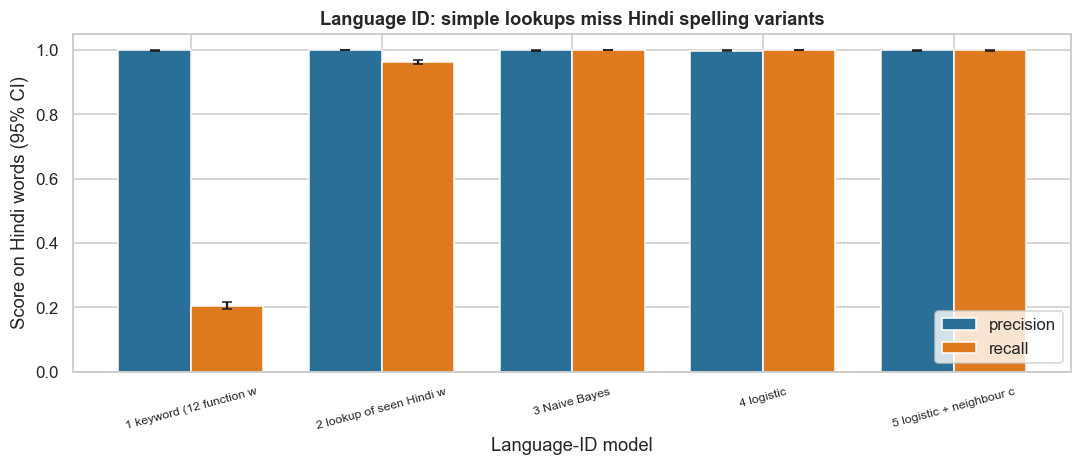

                                precision  recall     F1
model                                                   
1 keyword (12 function words)      1.0000  0.2050 0.3400
2 lookup of seen Hindi words       1.0000  0.9630 0.9810
3 Naive Bayes, char n-grams        0.9980  0.9990 0.9990
4 logistic, char n-grams           0.9980  0.9990 0.9980
5 logistic + neighbour context     0.9980  0.9990 0.9990


In [8]:
fig, ax = plt.subplots(figsize=(10, 4.4)); xs = np.arange(len(lid)); w = 0.38
ax.bar(xs - w / 2, lid.precision, w, yerr=[lid.precision - lid["P low"], lid["P high"] - lid.precision], label="precision", color="#2a6f97", capsize=3)
ax.bar(xs + w / 2, lid.recall, w, yerr=[lid.recall - lid["R low"], lid["R high"] - lid.recall], label="recall", color="#e07a1f", capsize=3)
ax.set_xticks(xs); ax.set_xticklabels([m[:1] + " " + m[2:].split(",")[0][:22] for m in lid.index], rotation=15, fontsize=8); ax.set_ylim(0, 1.05)
ax.set_xlabel("Language-ID model"); ax.set_ylabel("Score on Hindi words (95% CI)"); ax.set_title("Language ID: simple lookups miss Hindi spelling variants"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show(); print(lid[["precision", "recall", "F1"]].round(3).to_string())

**Takeaway:** «O711»

### 7.2 From words to queries: detection and damage to English queries

**(a) Why?** The translator is applied only to queries that contain at least one word tagged Hindi. A **missed** Hinglish query stays untranslated (search failure). A **false alarm** on an English query risks corrupting it. We measure both at query level on the test set (3,000 Hinglish and 3,000 English queries), with Wilson CIs.

#### Code

In [9]:
qy = tst.groupby("qid").y.max(); rows = []
for k, p in pred.items():
    qp = pd.Series(p, index=tst.index).groupby(tst.qid).max(); h = qy == 1; tp = int(((qp == 1) & h).sum()); fp = int(((qp == 1) & ~h).sum()); fn = int(((qp == 0) & h).sum())
    rl, rh = proportion_confint(tp, tp + fn, method="wilson"); fl, fh = proportion_confint(fp, int((~h).sum()), method="wilson")
    rows.append((k, tp / (tp + fn), rl, rh, fp / int((~h).sum()), fl, fh, tp / max(tp + fp, 1)))
qlev = pd.DataFrame(rows, columns=["model", "Hinglish query recall", "R low", "R high", "English false-alarm rate", "FA low", "FA high", "query precision"]).set_index("model")
qlev.round(4)

,Hinglish query recall,R low,R high,English false-alarm rate,FA low,FA high,query precision
model,,,,,,,
1 keyword (12 function words),0.2683,0.2528,0.2845,0.0000,0.0000,0.0013,1.0000
2 lookup of seen Hindi words,0.9747,0.9684,0.9797,0.0000,0.0000,0.0013,1.0000
"3 Naive Bayes, char n-grams",0.9993,0.9976,0.9998,0.0027,0.0014,0.0053,0.9973
"4 logistic, char n-grams",0.9993,0.9976,0.9998,0.0033,0.0018,0.0061,0.9967
5 logistic + neighbour context,0.9990,0.9971,0.9997,0.0020,0.0009,0.0044,0.9980


**Observation:** «O72»

#### Gate used from here on

We use model 5 as the **gate**: the translator touches a query only if model 5 tags at least one word Hindi. First we score all 150,000 log queries (needed for the pseudo-label corpus).

In [10]:
def lid_tags_batch(qlist):
    tk_ = [q.lower().split() for q in qlist]; rows = []
    for qi, tk in enumerate(tk_):
        n = len(tk)
        for i in range(n): rows.append((qi, tk[i], tk[i - 1] if i else "<s>", tk[i + 1] if i + 1 < n else "</s>"))
    d = pd.DataFrame(rows, columns=["qi", "tok", "prev", "next"]); u = d[["tok", "prev", "next"]].drop_duplicates().reset_index(drop=True); u["p"] = lrx.predict(feats(u, True))
    d = d.merge(u, on=["tok", "prev", "next"], how="left"); tags = [[] for _ in qlist]
    for qi, p in zip(d.qi.values, d.p.values): tags[qi].append(int(p))
    return tk_, tags
t0 = time.time(); _tk, _tags = lid_tags_batch(log.raw_query.tolist()); log["flag"] = [int(any(t)) for t in _tags]
print(f"Scored {len(log):,} log queries in {time.time() - t0:.0f}s | flagged as Hinglish: {log.flag.mean():.2%} (truth {log._is_hinglish.mean():.2%}) | recall {log.flag[log._is_hinglish == 1].mean():.3f} | false-alarm rate {log.flag[log._is_hinglish == 0].mean():.4f}")

Scored 150,000 log queries in 21s | flagged as Hinglish: 21.16% (truth 21.07%) | recall 0.999 | false-alarm rate 0.0014


**Observation:** «O721»

### 7.3 The translator: lexicon from parallel queries + spelling-aware classifier + learned reordering

We have no word alignments, only query pairs (Hinglish query, English query). The translator has three parts, all scikit-learn level:

1. **Lexicon induction.** For every query word we find the English word it co-occurs with most (cosine association of "word appears in query" and "word appears in translation"), and keep it if that English word appears in at least 40% of the query word's pairs; otherwise the word is a **dropped** word (ke, wala...). Words seen at least twice get an entry.
2. **Spelling-aware fallback.** A linear SVM on character 1-4 grams, trained on the lexicon entries, translates **unseen spellings** ("jootaa", "juuta").
3. **Learned reorderer.** After word translation the English words are still in Hindi order ("women for shoes"). A linear classifier on word-by-position features predicts which positions to keep and in which order ("2-1-0"), learned from the human pairs. Extra words ("for for", a stray "with") are dropped the same way.

**Two-stage training (as documented):** stage 1 = lexicon induced from **API pseudo-labels** on all flagged log queries (many, but the API never fixes non-standard spellings: its label for such a word is the word itself); stage 2 = lexicon induced from the **human-tagged** pairs, which overrides stage 1 and gets 3× weight in the classifier. The reorderer is trained on human pairs only (the API never reorders).

**Systems compared on the 3,000 Hinglish test queries**

| # | System |
|---|---|
| 1 | Pass-through (no translation) |
| 2 | Third-party API (pseudo-label source) |
| 3 | Stage 1 only: pseudo-label lexicon, no reordering |
| 4 | Human labels only: lexicon + classifier + reorderer |
| 5 | **Two-stage**: pseudo + human lexicon + reorderer |
| 6 | As 5 without the reorderer (ablation) |
| 7 | As 5 plus **query memory** (exact string seen in the human train set returns its human translation) |

#### Code

In [11]:
def norm(s): return " ".join(s.lower().split())
te = tes.copy(); te["q"] = te.raw_query.map(norm); te["gold"] = te.human_translation.map(norm); lg = log.set_index("query_id")
te["stratum"] = lg.loc[te.query_id, "_stratum"].values; te["tpl"] = lg.loc[te.query_id, "_template"].values; te["api"] = lg.loc[te.query_id, "api_translation"].map(norm).values
te["items"] = lg.loc[te.query_id, "_items"].values; te["colour"] = lg.loc[te.query_id, "_colour"].values; te["aud"] = lg.loc[te.query_id, "_audience"].values
tk_te, tags_te = lid_tags_batch(te.q.tolist()); te["flag"] = [int(any(t)) for t in tags_te]
htr = tg[(tg.split == "train") & tg.human_token_lang.str.contains("h")].copy(); htr["q"] = htr.raw_query.map(norm); htr["gold"] = htr.human_translation.map(norm)
et = tg[(tg.split == "test") & ~tg.human_token_lang.str.contains("h")].copy(); et["q"] = et.raw_query.map(norm)
_, tags_et = lid_tags_batch(et.q.tolist()); et["flag"] = [int(any(t)) for t in tags_et]
UNIV = sorted({w for q in tg.raw_query for w in q.lower().split()})
test_ids = set(tg.query_id[tg.split == "test"])

def induce(src, tgt, min_n=2, min_p=0.4):
    cs = CountVectorizer(token_pattern=r"\S+", binary=True, lowercase=False); ct = CountVectorizer(token_pattern=r"\S+", binary=True, lowercase=False)
    Xs = cs.fit_transform(src); Xt = ct.fit_transform(tgt); C = (Xs.T @ Xt).tocoo(); ns = np.asarray(Xs.sum(0)).ravel(); nt = np.asarray(Xt.sum(0)).ravel()
    d = pd.DataFrame({"r": C.row, "c": C.col, "cnt": C.data, "s": C.data / np.sqrt(ns[C.row] * nt[C.col])}).sort_values("s", ascending=False).drop_duplicates("r").set_index("r")
    vs = cs.get_feature_names_out(); vt = ct.get_feature_names_out(); lex = {}; cnt = {}
    for r in range(len(vs)):
        if ns[r] < min_n: continue
        cnt[vs[r]] = int(ns[r]); lex[vs[r]] = vt[int(d.loc[r, "c"])] if (r in d.index and d.loc[r, "cnt"] / ns[r] >= min_p) else ""
    return lex, cnt

def build_tok(lex, wts, aug=False):
    lab_of = lambda t: "<NULL>" if not lex[t] else ("<ID>" if lex[t] == t else lex[t])
    ts = list(lex); labs = [lab_of(t) for t in ts]; w = [wts[t] for t in ts]
    if aug:
        for t in list(ts):
            if len(t) >= 4:
                for i in (1, len(t) // 2): ts.append(t[:i] + t[i + 1:]); labs.append(lab_of(t)); w.append(0.3 * wts[t])
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4), sublinear_tf=True).fit(ts + UNIV); svc = LinearSVC(C=1.0).fit(vec.transform(ts), labs, sample_weight=w)
    pr = svc.predict(vec.transform(UNIV)); tok = {t: ("" if p == "<NULL>" else (t if p == "<ID>" else p)) for t, p in zip(UNIV, pr)}
    tok.update(lex); return tok

def merge_lex(lh, nh, lp=None, npp=None, hw=3.0):
    lex, w = {}, {}
    if lp is not None:
        for t, e in lp.items(): lex[t] = e; w[t] = npp[t] ** 0.5
    for t, e in lh.items(): lex[t] = e; w[t] = hw * nh[t] ** 0.5
    return lex, w

def align(L, G):
    used, pos = set(), []
    for g in G:
        for i, l in enumerate(L):
            if i not in used and l == g: used.add(i); pos.append(i); break
        else: return None
    return "-".join(map(str, pos))
def rfeat(L):
    n = len(L); f = {"len=%d" % n: 1}
    for i, t in enumerate(L): f["w%d=%s" % (i, t)] = 1; f["v%d=%s" % (n - 1 - i, t)] = 1
    for i in range(n - 1): f["b%d=%s_%s" % (i, L[i], L[i + 1])] = 1
    return f
def lexL(q, TOK): return [e for e in (TOK.get(t, t) for t in q.split()) if e]
def fit_reorder(Ls, Gs):
    X, yy = [], []
    for L, G in zip(Ls, Gs):
        lab = align(L, G)
        if lab is not None: X.append(rfeat(L)); yy.append(lab)
    dv = DictVectorizer(); m = LinearSVC(C=1.0).fit(dv.fit_transform(X), yy); return dv, m, len(yy)
def apply_reorder(Ls, ro):
    if ro is None or not Ls: return [" ".join(L) for L in Ls]
    dv, m, _ = ro; labs = m.predict(dv.transform([rfeat(L) for L in Ls])); out = []
    for L, lab in zip(Ls, labs):
        pos = [int(x) for x in lab.split("-")] if lab else []
        out.append(" ".join(L[p] for p in pos) if pos and max(pos) < len(L) else " ".join(L))
    return out
def translate(qs, flags, TOK, ro=None, memory=None):
    out = [None] * len(qs); idx, Ls = [], []
    for i, (q, f) in enumerate(zip(qs, flags)):
        if memory is not None and q in memory: out[i] = memory[q]
        elif not f: out[i] = q
        else: idx.append(i); Ls.append(lexL(q, TOK))
    for i, o in zip(idx, apply_reorder(Ls, ro)): out[i] = o
    return out

def fit_system(hdf, two_stage, aug=False, reorder=True):
    Hq, Gq = hdf.q.tolist(), hdf.gold.tolist(); lh, nh = induce(Hq, Gq)
    lex, w = merge_lex(lh, nh, LEX_P if two_stage else None, N_P if two_stage else None); TOK = build_tok(lex, w, aug)
    ro = fit_reorder([lexL(q, TOK) for q in Hq], [g.split() for g in Gq]) if reorder else None
    return TOK, ro

t0 = time.time()
pseudo_ids = log.query_id[(log.flag == 1) & ~log.query_id.isin(test_ids)].values
LEX_P, N_P = induce(log.raw_query.values[pseudo_ids].tolist(), log.api_translation.values[pseudo_ids].tolist())
TOK3 = build_tok(*merge_lex({}, {}, LEX_P, N_P))
TOK4, RO4 = fit_system(htr, False); TOK5, RO5 = fit_system(htr, True)
MEM = htr.groupby("q").gold.agg(lambda s: s.value_counts().index[0]).to_dict()
SYS = {"1 pass-through": [q if True else q for q in te.q],
       "2 third-party API": [a if f else q for a, q, f in zip(te.api, te.q, te.flag)],
       "3 stage 1 only (pseudo-labels, no reorder)": translate(te.q.tolist(), te.flag, TOK3),
       "4 human labels only": translate(te.q.tolist(), te.flag, TOK4, RO4),
       "5 two-stage (pseudo + human)": translate(te.q.tolist(), te.flag, TOK5, RO5),
       "6 two-stage, no reorderer": translate(te.q.tolist(), te.flag, TOK5),
       "7 two-stage + query memory": translate(te.q.tolist(), te.flag, TOK5, RO5, MEM)}
print(f"Pseudo-label corpus {len(pseudo_ids):,} queries -> lexicon {len(LEX_P):,} words | human lexicon from {len(htr):,} queries | reorderer trained on {RO5[2]:,} aligned pairs of {len(htr):,} | fitted in {time.time() - t0:.0f}s")
for k in ("3 stage 1 only (pseudo-labels, no reorder)", "5 two-stage (pseudo + human)", "7 two-stage + query memory"): print(f"  {k}:", list(zip(te.q.values[:4], SYS[k][:4])))
print("Examples (query -> truth):", list(zip(te.q.values[10:14], te.gold.values[10:14])))

Pseudo-label corpus 28,732 queries -> lexicon 1,671 words | human lexicon from 9,000 queries | reorderer trained on 8,036 aligned pairs of 9,000 | fitted in 43s
  3 stage 1 only (pseudo-labels, no reorder): [('jute', 'jute'), ('joota maazoot', 'joota maazoot'), ('kurshi', 'kurshi'), ('shafed chappal', 'shafed slippers')]
  5 two-stage (pseudo + human): [('jute', 'shoes'), ('joota maazoot', 'strong shoes'), ('kurshi', 'chair'), ('shafed chappal', 'white slippers')]
  7 two-stage + query memory: [('jute', 'shoes'), ('joota maazoot', 'strong shoes'), ('kurshi', 'chair'), ('shafed chappal', 'white slippers')]
Examples (query -> truth): [('chhaappal', 'slippers'), ('laadkiyon ke liye jutaa', 'shoes for girls'), ('blue chhappal', 'blue slippers'), ('thhaila laamba', 'long bag')]


**Observation (set-up):** «O730»

### 7.4 Which system is better? Exact match, BLEU, paired tests

**(a) Why?** BLEU is the documented metric, but queries are only 2-4 words, so corpus BLEU is coarse. **Exact match** (the whole English query is right) is the number a search team can act on. All systems are scored on the **same** 3,000 test queries, so the right test is **paired**: McNemar on exact match (Holm across comparisons, reference = system 5), and a **paired bootstrap** (400 resamples of queries) for BLEU CIs. BLEU is our own corpus-level 4-gram implementation (zero-count n-grams get 0.1), not SacreBLEU.

#### Code

In [12]:
def bleu_stats(h, r):
    hl, rl = h.split(), r.split(); m, t = [], []
    for n in range(1, 5):
        hc = Counter(tuple(hl[i:i + n]) for i in range(len(hl) - n + 1)); rc = Counter(tuple(rl[i:i + n]) for i in range(len(rl) - n + 1))
        m.append(sum(min(c, rc[g]) for g, c in hc.items())); t.append(max(len(hl) - n + 1, 0))
    return m + t + [len(hl), len(rl)]
def bleu_from(S):
    s = S.sum(0); m, t = s[:4].astype(float), s[4:8]; m = np.where(m == 0, 0.1, m); lp = np.mean(np.log(m / np.maximum(t, 1))); bp = 1.0 if s[8] > s[9] else np.exp(1 - s[9] / max(s[8], 1)); return 100 * bp * np.exp(lp)
def boot_bleu(S, B=400):
    n = len(S); out = []
    for lo in range(0, B, 100): idx = RNG.integers(0, n, (100, n)); out += [bleu_from(S[i]) for i in idx]
    return np.percentile(out, [2.5, 97.5])
gold = te.gold.tolist(); EX = {k: np.array([a == b for a, b in zip(v, gold)]) for k, v in SYS.items()}; BS = {k: np.array([bleu_stats(a, b) for a, b in zip(v, gold)]) for k, v in SYS.items()}
ref = "5 two-stage (pseudo + human)"; rows = []; pv = {}
for k in SYS:
    e = EX[k]; lo, hi = proportion_confint(e.sum(), len(e), method="wilson"); bl = boot_bleu(BS[k]); row = [k, e.mean(), lo, hi, bleu_from(BS[k]), bl[0], bl[1]]
    if k != ref:
        a, b = EX[ref], e; pv[k] = mcnemar([[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]], exact=False, correction=True).pvalue; row += [int((a & ~b).sum()), int((~a & b).sum())]
    else: row += [np.nan, np.nan]
    rows.append(row)
sy = pd.DataFrame(rows, columns=["system", "exact match", "EM low", "EM high", "BLEU", "BLEU low", "BLEU high", "only system 5 right", "only this system right"]).set_index("system")
sy["McNemar p vs 5"] = pd.Series({k: v for k, v in pv.items()}); ks = list(pv); sy.loc[ks, "p_holm"] = multipletests([pv[k] for k in ks], method="holm")[1]
print(f"Test: {len(te):,} Hinglish queries | flagged by the gate: {te.flag.mean():.1%}")
sy.round(4)

Test: 3,000 Hinglish queries | flagged by the gate: 99.9%


,exact match,EM low,EM high,BLEU,BLEU low,BLEU high,only system 5 right,only this system right,McNemar p vs 5,p_holm
system,,,,,,,,,,
1 pass-through,0.0000,0.0000,0.0013,0.2171,0.2020,0.2314,"2,551.0000",0.0000,0.0000,0.0000
2 third-party API,0.2017,0.1877,0.2164,7.8894,3.5481,10.4049,"1,950.0000",4.0000,0.0000,0.0000
"3 stage 1 only (pseudo-labels, no reorder)",0.2167,0.2023,0.2318,9.1802,4.0439,11.3415,"1,905.0000",4.0000,0.0000,0.0000
4 human labels only,0.9203,0.9101,0.9295,92.7265,91.2089,93.9242,1.0000,211.0000,0.0000,0.0000
5 two-stage (pseudo + human),0.8503,0.8371,0.8627,85.1531,82.5531,87.5563,NaN,NaN,NaN,NaN
"6 two-stage, no reorderer",0.5553,0.5375,0.5730,17.8643,15.2391,20.4726,885.0000,0.0000,0.0000,0.0000
7 two-stage + query memory,0.8610,0.8482,0.8729,85.5269,82.6950,88.0509,0.0000,32.0000,0.0000,0.0000


**(c)/(f) Observation:** «O74»

### 7.5 Head, Torso, Tail

**(a) Why?** The paper stratifies its test set by traffic. Head queries repeat and can be memorised; tail queries have rare spellings and combinations, and they are where translation has to generalise. We report exact match with Wilson CIs by stratum for the main systems, a **chi-square test** of independence for system 5, and the share of test queries whose exact string was in the human train set.

#### Code

In [13]:
main = ["2 third-party API", "4 human labels only", "5 two-stage (pseudo + human)", "7 two-stage + query memory"]; strata = ["head", "torso", "tail"]; rows = []
for k in main:
    for s in strata:
        m = (te.stratum == s).values; e = EX[k][m]; lo, hi = proportion_confint(e.sum(), len(e), method="wilson"); rows.append((k, s, e.mean(), lo, hi, len(e)))
st = pd.DataFrame(rows, columns=["system", "stratum", "exact match", "low", "high", "n"])
ct5 = pd.crosstab(te.stratum, EX[ref]).reindex(strata); chi = stats.chi2_contingency(ct5.values); te["seen"] = te.q.isin(set(htr.q))
seen_sh = te.groupby("stratum").seen.mean().reindex(strata); unseen_em = {s: EX[ref][((te.stratum == s) & ~te.seen).values].mean() for s in strata}
print(f"System 5 across strata: chi-square = {chi[0]:.1f}, df = 2, p = {chi[1]:.3g} | share of test strings seen in human train: " + ", ".join(f"{s} {seen_sh[s]:.1%}" for s in strata))
print("System 5 exact match on UNSEEN strings only: " + ", ".join(f"{s} {v:.1%}" for s, v in unseen_em.items()))
st.pivot(index="system", columns="stratum", values="exact match")[strata].round(4)

System 5 across strata: chi-square = 238.1, df = 2, p = 1.99e-52 | share of test strings seen in human train: head 95.1%, torso 23.6%, tail 0.0%
System 5 exact match on UNSEEN strings only: head 93.9%, torso 78.3%, tail 75.4%


stratum,head,torso,tail
system,,,
2 third-party API,0.4360,0.1150,0.0540
4 human labels only,0.9900,0.9010,0.8700
5 two-stage (pseudo + human),0.9890,0.8080,0.7540
7 two-stage + query memory,0.9960,0.8330,0.7540


**Observation:** «O75»

#### Chart

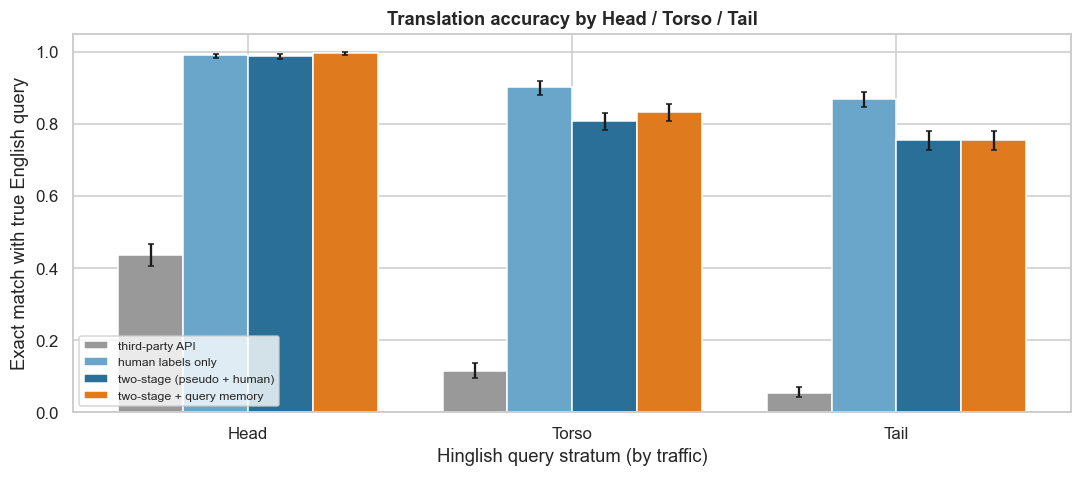

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.5)); w = 0.2; cols = ["#999999", "#6aa6c9", "#2a6f97", "#e07a1f"]
for j, k in enumerate(main):
    d = st[st.system == k].set_index("stratum").reindex(strata); ax.bar(np.arange(3) + (j - 1.5) * w, d["exact match"], w, yerr=[d["exact match"] - d.low, d.high - d["exact match"]], label=k[2:], color=cols[j], capsize=2)
ax.set_xticks(range(3)); ax.set_xticklabels(["Head", "Torso", "Tail"]); ax.set_ylim(0, 1.05); ax.set_xlabel("Hinglish query stratum (by traffic)"); ax.set_ylabel("Exact match with true English query"); ax.set_title("Translation accuracy by Head / Torso / Tail"); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

**Takeaway:** «O751»

### 7.6 Where does it fail? Accuracy by query shape

**(a) Why?** An average hides structural failures: reordering ("X ke liye Y"), negation ("bina... wala"), price phrases, and articulation-gap phrases that need whole-phrase meaning. We split system 5 and system 7 exact match by template (hidden label, evaluation only), with Wilson CIs and a chi-square test.

#### Code

In [15]:
tp_ = te.assign(e5=EX[ref], e7=EX["7 two-stage + query memory"], e2=EX["2 third-party API"]).groupby("tpl").agg(n=("e5", "size"), api=("e2", "mean"), two_stage=("e5", "mean"), with_memory=("e7", "mean")).sort_values("two_stage")
cil = [proportion_confint(int(round(r.two_stage * r.n)), int(r.n), method="wilson") for r in tp_.itertuples()]; tp_["low"] = [c[0] for c in cil]; tp_["high"] = [c[1] for c in cil]
ct6 = pd.crosstab(te.tpl, EX[ref]); chi6 = stats.chi2_contingency(ct6.values)
print(f"System 5 exact match differs by template: chi-square = {chi6[0]:.1f}, df = {chi6[2]}, p = {chi6[1]:.3g}")
tp_.round(4)

System 5 exact match differs by template: chi-square = 309.7, df = 11, p = 8.05e-60


,n,api,two_stage,with_memory,low,high
tpl,,,,,,
with,160,0.0438,0.4250,0.4562,0.3510,0.5025
gap,125,0.0000,0.6480,0.6880,0.5610,0.7262
price,301,0.0199,0.8372,0.8372,0.7913,0.8746
aud_col_item,93,0.0215,0.8387,0.8387,0.7508,0.8997
adj_col_item,104,0.1538,0.8462,0.8462,0.7646,0.9030
without,154,0.1039,0.8506,0.8506,0.7859,0.8984
item_adj,262,0.0344,0.8855,0.8855,0.8412,0.9186
brand_item,192,0.3802,0.8906,0.8906,0.8386,0.9273
col_item,559,0.3131,0.8927,0.8945,0.8643,0.9157


**Observation:** «O76»

#### Chart

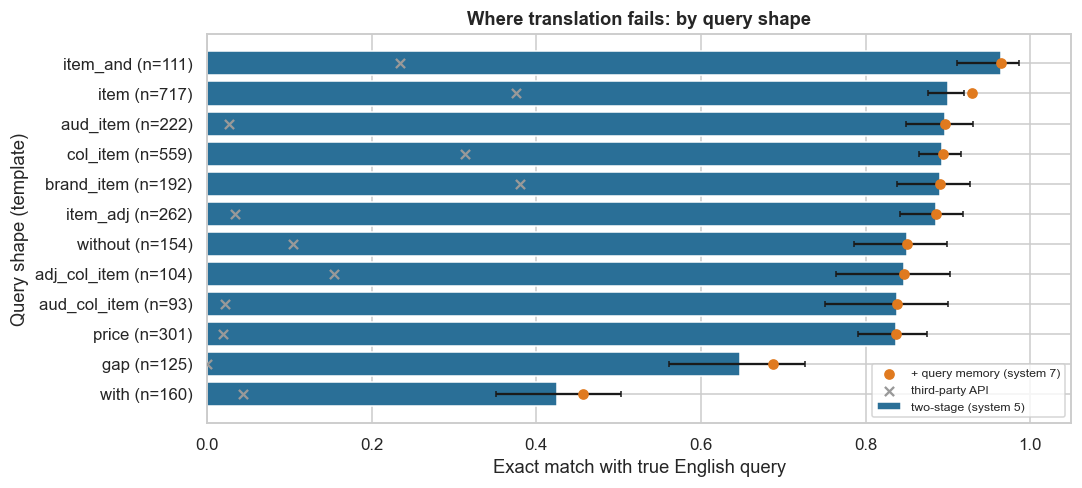

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.6)); yy = np.arange(len(tp_))
ax.barh(yy, tp_.two_stage, xerr=[tp_.two_stage - tp_.low, tp_.high - tp_.two_stage], color="#2a6f97", capsize=2, label="two-stage (system 5)"); ax.scatter(tp_.with_memory, yy, color="#e07a1f", zorder=3, label="+ query memory (system 7)"); ax.scatter(tp_.api, yy, color="#999999", marker="x", zorder=3, label="third-party API")
ax.set_yticks(yy); ax.set_yticklabels([f"{t} (n={n})" for t, n in zip(tp_.index, tp_.n)]); ax.set_xlim(0, 1.05); ax.set_xlabel("Exact match with true English query"); ax.set_ylabel("Query shape (template)"); ax.set_title("Where translation fails: by query shape"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Takeaway:** «O761»

### 7.7 How many human labels do we need? Learning curve

**(a) Why?** Human tagging is the expensive part (the paper's in-house set is under 1.5% of its labelled data). We refit the whole translator on random subsets of the human train set, **with and without** the pseudo-label stage, 3 repeats per size (the full 9,000 set once), and score exact match on the same test queries. Test-set sampling error is small (±1.5 points); the spread across repeats shows training-set variation.

#### Code

In [17]:
t0 = time.time(); sizes = [250, 500, 1000, 2000, 4000, 9000]; rows = []
def em_of(TOK, ro): return np.mean([a == b for a, b in zip(translate(te.q.tolist(), te.flag, TOK, ro), gold)])
for n in sizes:
    for rep in range(1 if n == 9000 else 3):
        sub = htr.sample(n=n, random_state=SEED + rep) if n < 9000 else htr
        for two in (False, True):
            TOK_, ro_ = fit_system(sub, two); rows.append((n, rep, "human labels only" if not two else "two-stage (pseudo + human)", em_of(TOK_, ro_)))
lc = pd.DataFrame(rows, columns=["n human labels", "rep", "system", "exact match"]); lcs = lc.groupby(["system", "n human labels"])["exact match"].agg(["mean", "min", "max"]).reset_index()
print(f"Learning curve fitted in {time.time() - t0:.0f}s ({len(lc)} fits)")
lcs.pivot(index="n human labels", columns="system", values="mean").round(4)

Learning curve fitted in 57s (32 fits)


system,human labels only,two-stage (pseudo + human)
n human labels,,
250,0.4567,0.3453
500,0.6619,0.4554
1000,0.7570,0.5460
2000,0.8518,0.6820
4000,0.8933,0.7666
9000,0.9203,0.8503


**Observation:** «O77»

#### Chart

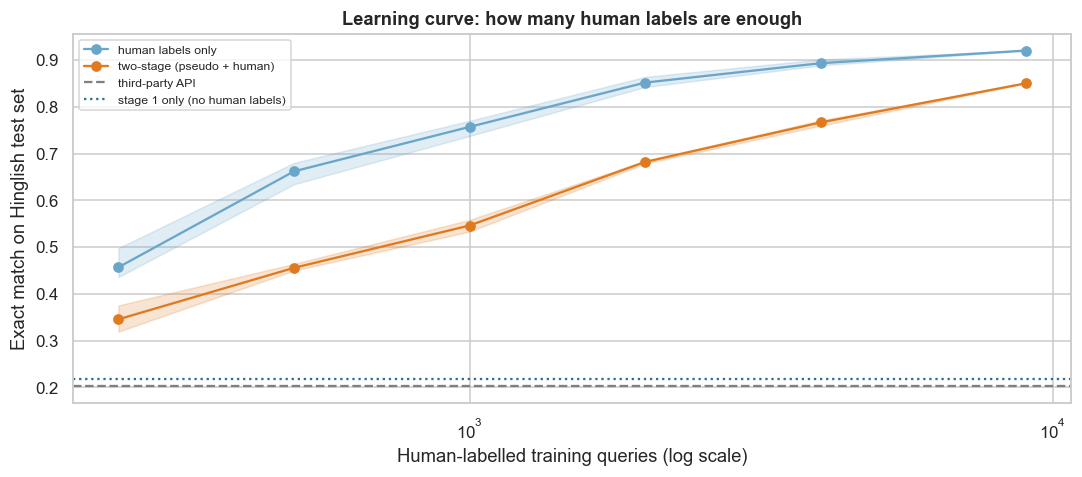

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for s, c in (("human labels only", "#6aa6c9"), ("two-stage (pseudo + human)", "#e07a1f")):
    d = lcs[lcs.system == s]; ax.plot(d["n human labels"], d["mean"], "o-", color=c, label=s); ax.fill_between(d["n human labels"], d["min"], d["max"], color=c, alpha=0.2)
ax.axhline(EX["2 third-party API"].mean(), color="grey", ls="--", label="third-party API"); ax.axhline(EX["3 stage 1 only (pseudo-labels, no reorder)"].mean(), color="#2a6f97", ls=":", label="stage 1 only (no human labels)")
ax.set_xscale("log"); ax.set_xlabel("Human-labelled training queries (log scale)"); ax.set_ylabel("Exact match on Hinglish test set"); ax.set_title("Learning curve: how many human labels are enough"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Takeaway:** «O771»

### 7.8 Does DropChar augmentation help?

The paper tests augmentations (DropChar: drop a character from 30-50% of words; masking; word-order permutation) and finds mixed effects. Our analogue for a character-n-gram classifier: add two one-character-dropped copies of every lexicon word (weight 0.3) when training. We compare system 5 with the augmented version on the same test queries (McNemar), overall and on the tail.

#### Code

In [19]:
TOKa, ROa = fit_system(htr, True, aug=True); outa = translate(te.q.tolist(), te.flag, TOKa, ROa); ea = np.array([a == b for a, b in zip(outa, gold)]); eb = EX[ref]; tail = (te.stratum == "tail").values
def mc_p(a, b): return mcnemar([[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]], exact=True).pvalue
d = ea.astype(int) - eb.astype(int); bs = [d[RNG.integers(0, len(d), len(d))].mean() for _ in range(1000)]
aug = pd.DataFrame({"system 5": [eb.mean(), eb[tail].mean()], "with DropChar": [ea.mean(), ea[tail].mean()]}, index=["exact match (all)", "exact match (tail)"]); aug["difference"] = aug["with DropChar"] - aug["system 5"]
print(f"Overall difference {d.mean():+.4f} (95% bootstrap CI {np.percentile(bs, 2.5):+.4f} to {np.percentile(bs, 97.5):+.4f}) | only-aug right {int((ea & ~eb).sum())}, only-base right {int((~ea & eb).sum())} | McNemar exact p = {mc_p(ea, eb):.3g} | tail-only p = {mc_p(ea[tail], eb[tail]):.3g}")
aug.round(4)

Overall difference +0.0047 (95% bootstrap CI +0.0020 to +0.0077) | only-aug right 17, only-base right 3 | McNemar exact p = 0.00258 | tail-only p = 0.227


,system 5,with DropChar,difference
exact match (all),0.8503,0.8550,0.0047
exact match (tail),0.7540,0.7590,0.0050


**Observation:** «O78»

### 7.9 Does translation improve search? Success@10 on a catalogue

**(a) Why?** Exact match is a proxy. The business question is whether shoppers find what they meant. We index the 11,800 English product titles with TF-IDF (word level), run each query as typed and as translated, and call a query **successful** if one of the top 10 products has the intended item (and colour, and audience, when the query states them). Queries with no relevant product in the catalogue are dropped. The "true translation" row is the upper bound. Negation ("without laces") and price caps are not scored, and a plain TF-IDF engine cannot honour them, which is a stated limitation. **McNemar** and a paired bootstrap compare raw vs translated.

#### Code

In [20]:
cat_ = cat.sample(frac=1, random_state=SEED).reset_index(drop=True); pv_ = TfidfVectorizer(sublinear_tf=True).fit(cat_.title); P = pv_.transform(cat_.title).T.tocsc()
item_arr, col_arr, aud_arr = cat_.item.values, cat_.colour.values, cat_.audience.values; MC = {}
def rel_mask(items, colour, aud):
    k = (items, colour, aud)
    if k not in MC:
        m = np.isin(item_arr, items.split("|"))
        if colour: m = m & (col_arr == colour)
        if aud: m = m & (aud_arr == aud)
        MC[k] = m
    return MC[k]
def search_eval(queries, meta):
    Q = pv_.transform(queries); n = len(queries); hit = np.zeros(n, bool); rr = np.zeros(n); keys = list(zip(meta["items"], meta["colour"], meta["aud"]))
    for lo in range(0, n, 500):
        S = (Q[lo:lo + 500] @ P).toarray(); top = np.argsort(-S, axis=1)[:, :10]; has = S.max(1) > 0
        for j in range(S.shape[0]):
            if not has[j]: continue
            r = rel_mask(*keys[lo + j])[top[j]]
            if r.any(): hit[lo + j] = True; rr[lo + j] = 1 / (1 + int(np.argmax(r)))
    return hit, rr
okq = np.array([rel_mask(a, b, c).any() for a, b, c in zip(te["items"], te.colour, te.aud)]); meta = te[okq]
RS = {"as typed (raw)": te.q.tolist(), "third-party API": SYS["2 third-party API"], "two-stage translator (5)": SYS[ref], "+ query memory (7)": SYS["7 two-stage + query memory"], "true translation (upper bound)": gold}
RET = {k: search_eval([v[i] for i in np.where(okq)[0]], meta) for k, v in RS.items()}; strat_ok = meta.stratum.values; rows = []
for k, (h_, r_) in RET.items():
    lo, hi = proportion_confint(h_.sum(), len(h_), method="wilson"); row = {"queries": k, "success@10": h_.mean(), "low": lo, "high": hi, "MRR@10": r_.mean()}
    for s in strata: row[s] = h_[strat_ok == s].mean()
    rows.append(row)
rt = pd.DataFrame(rows).set_index("queries"); a_, b_ = RET["two-stage translator (5)"][0], RET["as typed (raw)"][0]
dh = a_.astype(int) - b_.astype(int); bsd = [dh[RNG.integers(0, len(dh), len(dh))].mean() for _ in range(1000)]; pm = mcnemar([[int((a_ & b_).sum()), int((a_ & ~b_).sum())], [int((~a_ & b_).sum()), int((~a_ & ~b_).sum())]], exact=False, correction=True).pvalue
print(f"Queries with a relevant product: {int(okq.sum()):,} of {len(te):,} | translated vs raw: gain {dh.mean():+.4f} (95% CI {np.percentile(bsd, 2.5):+.4f} to {np.percentile(bsd, 97.5):+.4f}), only translated succeeds {int((a_ & ~b_).sum())}, only raw succeeds {int((~a_ & b_).sum())}, McNemar p = {pm:.3g}")
rt.round(4)

Queries with a relevant product: 2,985 of 3,000 | translated vs raw: gain +0.7313 (95% CI +0.7149 to +0.7471), only translated succeeds 2196, only raw succeeds 13, McNemar p = 0


,success@10,low,high,MRR@10,head,torso,tail
queries,,,,,,,
as typed (raw),0.1903,0.1766,0.2048,0.1651,0.0840,0.2485,0.2391
third-party API,0.4891,0.4712,0.5070,0.4509,0.5470,0.4870,0.4326
two-stage translator (5),0.9216,0.9114,0.9307,0.9053,0.9900,0.8918,0.8825
+ query memory (7),0.9290,0.9192,0.9377,0.9130,0.9960,0.9078,0.8825
true translation (upper bound),0.9987,0.9966,0.9995,0.9923,1.0000,1.0000,0.9959


**Observation:** «O79»

#### Chart

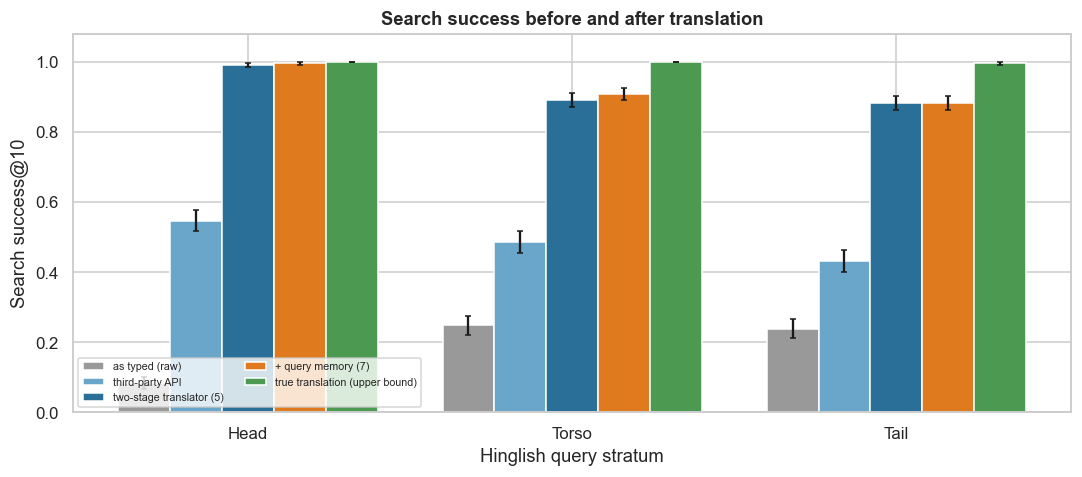

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.5)); names = list(RET); cols = ["#999999", "#6aa6c9", "#2a6f97", "#e07a1f", "#4c9a52"]; w = 0.16
for j, k in enumerate(names):
    vals = [RET[k][0][strat_ok == s].mean() for s in strata]; ns_ = [(strat_ok == s).sum() for s in strata]; err = [1.96 * np.sqrt(v * (1 - v) / n) for v, n in zip(vals, ns_)]
    ax.bar(np.arange(3) + (j - 2) * w, vals, w, yerr=err, label=k, color=cols[j], capsize=2)
ax.set_xticks(range(3)); ax.set_xticklabels(["Head", "Torso", "Tail"]); ax.set_ylim(0, 1.08); ax.set_xlabel("Hinglish query stratum"); ax.set_ylabel("Search success@10"); ax.set_title("Search success before and after translation"); ax.legend(fontsize=7, loc="lower left", ncol=2)
plt.tight_layout(); plt.show()

**Takeaway:** «O791»

### 7.10 Damage to English queries, and latency: teacher vs memoised student

**(a) Why?** A good translator is useless if it corrupts English queries or is slow. (1) We run the **gate + translator** on the 3,000 English test queries, and also the translator **without a gate** (apply to every query), and count queries that change. (2) The paper distils a slow teacher into a fast quantised student (BLEU 51.3 to 50.8, p95 about 200 ms to about 47 ms). Our analogue is **memoisation**: cache the teacher's output for every word and word-context already seen, and call the teacher only on a miss. We time both, one query at a time (single thread), on 1,000 Hinglish test queries. Hardware timings are specific to this machine.

#### Code

In [22]:
en_q = et.q.tolist(); out_g = translate(en_q, et.flag, TOK5, RO5); out_u = translate(en_q, [1] * len(en_q), TOK5, RO5)
chg_g = np.mean([a != b for a, b in zip(out_g, en_q)]); chg_u = np.mean([a != b for a, b in zip(out_u, en_q)])
def teacher(q):
    tk, tags = lid_tags_batch([q]); return translate([q], [int(any(tags[0]))], TOK5, RO5)[0]
CACHE = {}
def student(q):
    if q in CACHE: return CACHE[q]
    out = teacher(q); CACHE[q] = out; return out
# warm the student on the human train queries (what a cache would hold), then time on test queries
wq = htr.q.drop_duplicates().tolist()
for q in wq: student(q)
sample_q = te.q.tolist()[:1000]
def timeit(fn, qs):
    ts = []; outs = []
    for q in qs: t0 = time.perf_counter(); outs.append(fn(q)); ts.append((time.perf_counter() - t0) * 1000)
    return np.array(ts), outs
t_t, o_t = timeit(teacher, sample_q); t_s, o_s = timeit(student, sample_q)
em_t = np.mean([a == b for a, b in zip(o_t, te.gold.tolist()[:1000])]); em_s = np.mean([a == b for a, b in zip(o_s, te.gold.tolist()[:1000])]); hit = np.mean([q in CACHE for q in sample_q])
lat = pd.DataFrame({"teacher": [np.percentile(t_t, 50), np.percentile(t_t, 95), t_t.mean(), em_t], "memoised student": [np.percentile(t_s, 50), np.percentile(t_s, 95), t_s.mean(), em_s]}, index=["p50 ms", "p95 ms", "mean ms", "exact match (1,000 queries)"])
print(f"English test queries changed: gated {chg_g:.2%} | translator applied to every query (no gate) {chg_u:.2%} | cache hit rate on the 1,000 timing queries before timing: {np.mean([q in set(wq) for q in sample_q]):.1%} | outputs identical teacher vs student: {np.mean([a == b for a, b in zip(o_t, o_s)]):.1%}")
lat.round(3)

English test queries changed: gated 0.00% | translator applied to every query (no gate) 3.10% | cache hit rate on the 1,000 timing queries before timing: 40.6% | outputs identical teacher vs student: 100.0%


,teacher,memoised student
p50 ms,9.5550,7.9060
p95 ms,15.4100,14.7780
mean ms,12.6130,8.9860
"exact match (1,000 queries)",0.8450,0.8450


**Observation:** «O710»

### 7.11 Sample sizes: test set for model comparison, and an A/B test

**(a) Why?** (1) How many tagged test queries do we need to confirm that one translator beats another by 1, 2 or 5 points of exact match? Using the observed discordance between system 5 and system 4 (queries where exactly one is right), the paired sample size is n = (z<sub>α/2</sub>√p<sub>d</sub> + z<sub>β</sub>√(p<sub>d</sub> − d²))² / d². (2) How many **searches** does an A/B test need to detect a change in search success among Hinglish queries, given only about 21% of queries are Hinglish? 80% power, α = 0.05, two-sided, control success rate from the raw column above.

#### Code

In [23]:
a4, b4 = EX["4 human labels only"], EX[ref]; pd_ = np.mean(a4 != b4); rows = []
for d in (0.01, 0.02, 0.05): rows.append((f"{d:.0%} EM difference", int(np.ceil((1.96 * np.sqrt(pd_) + 0.84 * np.sqrt(max(pd_ - d ** 2, 1e-9))) ** 2 / d ** 2))))
p0 = RET["as typed (raw)"][0].mean(); rows2 = []
for rel in (0.05, 0.10, 0.20):
    p1 = min(p0 * (1 + rel), 0.999); n_h = int(np.ceil((1.96 + 0.84) ** 2 * (p0 * (1 - p0) + p1 * (1 - p1)) / (p1 - p0) ** 2)); rows2.append((f"+{rel:.0%} relative success", p0, p1, n_h, int(np.ceil(n_h / 0.21))))
print(f"Observed discordance between systems 4 and 5: {pd_:.3f}")
print(pd.DataFrame(rows, columns=["target", "paired test queries needed"]).set_index("target").to_string())
pd.DataFrame(rows2, columns=["lift", "control success", "treatment success", "Hinglish searches per arm", "all searches per arm (21% Hinglish)"]).set_index("lift").round(4)

Observed discordance between systems 4 and 5: 0.071
                  paired test queries needed
target                                      
1% EM difference                        5538
2% EM difference                        1383
5% EM difference                         220


,control success,treatment success,Hinglish searches per arm,all searches per arm (21% Hinglish)
lift,,,,
+5% relative success,0.1903,0.1998,27192,129486
+10% relative success,0.1903,0.2093,6920,32953
+20% relative success,0.1903,0.2283,1788,8515


**Observation:** «O711b»

## 8. ML Section — what we built and what is beyond it

- **What we built:** a language-ID classifier (logistic regression on character n-grams plus neighbours), a word-translation lexicon induced from parallel queries, a character n-gram SVM for unseen spellings, and a linear reorderer. No neural network, no hyper-parameter tuning (C = 1 everywhere).
- **Beyond this notebook:** the paper's seq2seq models (BART, T5, mT5, mBART) learn translation, spelling noise and reordering jointly, and are distilled and quantised for latency. A production system would also use a CRF or neural tagger for language ID and subword tokens.

#### What the language-ID model learned

In [24]:
fn = np.array(["c:" + f for f in vec_c.get_feature_names_out()] + ["x:" + f for f in vec_x.get_feature_names_out()]); co = lrx.coef_[0]
top = pd.DataFrame({"Hindi-leaning features": fn[np.argsort(-co)[:10]], "weight": np.sort(co)[::-1][:10], "English-leaning features": fn[np.argsort(co)[:10]], "weight ": np.sort(co)[:10]})
top

,Hindi-leaning features,weight,English-leaning features,weight
0,c:a,9.2322,c:s,-6.2023
1,c:i,6.3399,c:s,-4.2581
2,c:a,5.6209,c:r,-4.1913
3,c:aa,5.4622,c:9,-4.0441
4,x:P_ke,4.7207,c:p,-3.7363
5,c:al,4.1768,c:er,-3.3601
6,c:ha,4.0596,c:er,-3.2012
7,c:oo,3.9204,c:re,-3.1350
8,c:ee,3.5477,c:g,-3.0121
9,c:na,3.1962,c:nd,-2.9801


**Observation:** «O8»

## 9. Business Translation — ₹ impact

Assumptions (D-13-07, all **assumed**, not documented): 1 crore searches a day; Hinglish share 21% (documented; 15% and 25% as scenarios); a successful search leads to an order with probability 5% and a failed one 1% (gap 4 points; 2 and 5 in the scenarios); average order ₹650 at 12% contribution margin. The gain in success@10 comes from section 7.9 (two-stage translator vs raw queries) with its bootstrap CI; a **simulation-to-real haircut** shrinks it (100% best, 50% base, 25% worst) because real queries are messier than simulated ones.

#### Code

In [25]:
Q_DAY, AOV, MG = 1e7, 650, 0.12
def crore(delta, share, gap, hair): return delta * hair * Q_DAY * share * gap * AOV * MG * 365 / 1e7
base_d, lo_d, hi_d = dh.mean(), np.percentile(bsd, 2.5), np.percentile(bsd, 97.5)
sc = pd.DataFrame({"success gain (points)": [hi_d * 100, base_d * 100, lo_d * 100], "Hinglish share": [0.25, 0.21, 0.15], "order gap (success - fail)": [0.05, 0.04, 0.02], "sim-to-real haircut": [1.0, 0.5, 0.25]}, index=["best", "base", "worst"])
sc["extra orders / day (thousand)"] = [d / 100 * h * Q_DAY * s * g / 1e3 for d, s, g, h in zip(sc.iloc[:, 0], sc.iloc[:, 1], sc.iloc[:, 2], sc.iloc[:, 3])]
sc["₹ crore / year"] = [crore(d / 100, s, g, h) for d, s, g, h in zip(sc.iloc[:, 0], sc.iloc[:, 1], sc.iloc[:, 2], sc.iloc[:, 3])]
print(f"Gain in search success@10 on Hinglish queries: {base_d:+.3f} (95% CI {lo_d:+.3f} to {hi_d:+.3f})")
sc.round(3)

Gain in search success@10 on Hinglish queries: +0.731 (95% CI +0.715 to +0.747)


,success gain (points),Hinglish share,order gap (success - fail),sim-to-real haircut,extra orders / day (thousand),₹ crore / year
best,74.7070,0.2500,0.0500,1.0000,93.3840,265.8630
base,73.1320,0.2100,0.0400,0.5000,30.7160,87.4470
worst,71.4910,0.1500,0.0200,0.2500,5.3620,15.2650


**Takeaway (business reading):** «O9»

## 10. Recommendation and Decision

«O10»

## 11. Risks, Limitations and Next Steps

- **Simulated language:** transliteration variants, word order and query shapes were generated by rules we wrote, so the translator can learn them. Real Hinglish has far more variety (new words, slang, mixed scripts). Re-measure on real tagged queries.
- **Test leakage by repetition:** head query strings repeat between train and test, as in real logs; the unseen-string numbers in 7.5 are the honest generalisation estimate.
- **Search metric is simplified:** TF-IDF on titles, relevance from structured intent, no negation or price handling, no personalisation or ranking. Confirm in a live A/B test with guardrails.
- **Pseudo-label noise is systematic:** the API's errors (non-standard spellings left as they are) are not random, so more pseudo-labelled data does not remove them.
- **Documented vs ours:** the paper's BLEU values are for a neural seq2seq model on real data; none of our numbers are comparable.
- **Next steps:** error-driven human tagging of tail spellings, a phrase table or retrieval fallback for articulation-gap queries, a seq2seq model once the simple pipeline is a measured baseline, query-intent classification after translation.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Cosine association (query word s, English word t) | C(s,t) / √(n<sub>s</sub> n<sub>t</sub>), C = number of pairs where both appear |
| Keep rule | translation kept if C(s,t) / n<sub>s</sub> ≥ 0.4, else the word is dropped |
| Corpus BLEU | BP · exp(mean<sub>n=1..4</sub> log(matches<sub>n</sub> / total<sub>n</sub>)); BP = exp(1 − ref/hyp) if hyp ≤ ref |
| Exact match | output equals the true English query after lower-casing and whitespace normalisation |
| Success@10 | at least one of the top 10 products has the intended item (and stated colour and audience) |
| McNemar | test on queries where exactly one of two systems is right |
| Paired sample size | n = (z<sub>α/2</sub>√p<sub>d</sub> + z<sub>β</sub>√(p<sub>d</sub> − d²))² / d² |

| Term | Meaning |
|---|---|
| Hinglish | Hindi words typed in English letters, often mixed with English |
| Transliteration variant | A different Latin spelling of the same Hindi word (juta, jootaa) |
| Articulation gap | The shopper describes the product instead of naming it |
| Pseudo-label | A cheap, noisy label from a third-party tool |
| Head / Torso / Tail | Frequent, middle and rare queries (thirds of traffic) |
| Gate | The language-ID step that decides whether to translate a query |
| Memoisation | Caching a model's output so the model runs only on new inputs |